# Scenario: Federated Handwriting Recognition in a Mobile Learning App

Imagine a mobile learning app that recognizes handwritten digits.

- Each student's handwriting images must remain on the student's phone or tablet.
- Different students are practicing different digit groups, so their local data are **non-IID**.
- Devices also have different battery/compute availability, so they perform different amounts of local training.

In this toy experiment:

| Client | Main digits | Local gradient steps |
|---|---:|---:|
| 1 | 0–1 | 1 |
| 2 | 2–3 | 5 |
| 3 | 4–5 | 10 |
| 4 | 6–7 | 20 |
| 5 | 8–9 | 40 |

### Research question

**How can we let each device learn from its own local handwriting data without allowing powerful devices to drift too far toward their biased local distribution?**

We first run **FedAvg** as the baseline, then introduce the **FedProx** proximal term as a direct response to this failure mode.


# Week 7 Research Mini-Lab: From a Problem to FedProx

## Research problem

We deliberately create two sources of heterogeneity:

1. **Statistical heterogeneity:** each client mainly owns two digit classes.
2. **System heterogeneity:** clients perform different numbers of local steps: `[1, 5, 10, 20, 40]`.

With FedAvg, clients that train longer can move much farther away from the current global model. Under non-IID data, those directions can also disagree.

### Baseline local objective

For client \(k\),

\[
\min_W F_k(W)
\]

### FedProx idea

Add a proximal penalty around the current global model \(W^t\):

\[
\min_W F_k(W) + \frac{\mu}{2}\|W-W^t\|_2^2
\]

The additional gradient is simply:

\[
\mu(W-W^t)
\]

So the implementation change is very small, but it directly addresses the **client-drift problem**.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 7
np.random.seed(SEED)

## 1. Create heterogeneous clients

In [2]:
digits = load_digits()

X = digits.data.astype(np.float64) / 16.0
X = np.c_[X, np.ones(len(X))]
y = digits.target.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

pairs = [(0, 1), (2, 3), (4, 5), (6, 7), (8, 9)]

client_indices = [
    np.where((y_train == a) | (y_train == b))[0]
    for a, b in pairs
]

local_steps = [1, 5, 10, 20, 40]

for k, (pair, idx, steps) in enumerate(
    zip(pairs, client_indices, local_steps),
    start=1
):
    print(
        f"Client {k}: labels={pair}, "
        f"samples={len(idx)}, local_steps={steps}"
    )

Client 1: labels=(0, 1), samples=287, local_steps=1
Client 2: labels=(2, 3), samples=288, local_steps=5
Client 3: labels=(4, 5), samples=291, local_steps=10
Client 4: labels=(6, 7), samples=288, local_steps=20
Client 5: labels=(8, 9), samples=283, local_steps=40


## 2. Use a simple softmax classifier

A linear softmax model keeps the code short enough to focus on the federated-learning mechanism.

In [3]:
NUM_CLASSES = 10

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / exp_z.sum(axis=1, keepdims=True)


def ce_gradient(W, Xb, yb):
    probs = softmax(Xb @ W)
    targets = np.eye(NUM_CLASSES)[yb]

    return Xb.T @ (probs - targets) / len(Xb)


def test_accuracy(W):
    pred = np.argmax(X_test @ W, axis=1)

    return np.mean(pred == y_test)

def local_train(W_global, indices, steps, lr=0.5, mu=0.0):

    W = W_global.copy()

    X_local = X_train[indices]
    y_local = y_train[indices]

    for _ in range(steps):

        grad = ce_gradient(
            W,
            X_local,
            y_local
        )

        if mu > 0:
            grad = grad + mu * (W - W_global)

        W = W - lr * grad

    return W

## 3. Translate the FedProx equation into code

The only new term is `mu * (W - W_global)`.

In [4]:
def aggregate(local_models, client_sizes):

    weights = np.asarray(
        client_sizes,
        dtype=float
    )

    weights = weights / weights.sum()

    return sum(
        alpha * Wk
        for alpha, Wk in zip(
            weights,
            local_models
        )
    )

## 4. Federated training loop

In [5]:
def run_federated(
    mu=0.0,
    rounds=20,
    lr=0.5
):

    W = np.zeros(
        (X_train.shape[1], NUM_CLASSES)
    )

    accuracy_history = []
    drift_history = []

    client_sizes = [
        len(idx)
        for idx in client_indices
    ]

    for round_id in range(1, rounds + 1):

        local_models = [
            local_train(
                W,
                idx,
                steps,
                lr=lr,
                mu=mu
            )
            for idx, steps in zip(
                client_indices,
                local_steps
            )
        ]

        drift = np.mean([
            np.linalg.norm(Wk - W)
            for Wk in local_models
        ])

        drift_history.append(drift)

        W = aggregate(
            local_models,
            client_sizes
        )

        accuracy_history.append(
            test_accuracy(W)
        )

        print(
            f"Round {round_id:02d} | "
            f"accuracy={accuracy_history[-1]:.3f} | "
            f"drift={drift:.3f}"
        )

    return (
        np.asarray(accuracy_history),
        np.asarray(drift_history)
    )

## 5. Compare the baseline and the proposed fix

The same data split, learning rate, rounds, and local-step schedule are used for both methods.

In [6]:
fedavg_acc, fedavg_drift = run_federated(mu=0.0)
fedprox_acc, fedprox_drift = run_federated(mu=0.2)

print()
print(f"FedAvg final accuracy : {fedavg_acc[-1]:.3f}")
print(f"FedProx final accuracy : {fedprox_acc[-1]:.3f}")
print(f"FedAvg mean drift : {fedavg_drift.mean():.3f}")
print(f"FedProx mean drift : {fedprox_drift.mean():.3f}")

Round 01 | accuracy=0.361 | drift=2.344
Round 02 | accuracy=0.494 | drift=2.158
Round 03 | accuracy=0.564 | drift=2.019
Round 04 | accuracy=0.600 | drift=1.912
Round 05 | accuracy=0.619 | drift=1.829
Round 06 | accuracy=0.631 | drift=1.761
Round 07 | accuracy=0.656 | drift=1.704
Round 08 | accuracy=0.686 | drift=1.655
Round 09 | accuracy=0.722 | drift=1.613
Round 10 | accuracy=0.742 | drift=1.575
Round 11 | accuracy=0.756 | drift=1.541
Round 12 | accuracy=0.769 | drift=1.510
Round 13 | accuracy=0.778 | drift=1.482
Round 14 | accuracy=0.789 | drift=1.455
Round 15 | accuracy=0.814 | drift=1.430
Round 16 | accuracy=0.817 | drift=1.407
Round 17 | accuracy=0.822 | drift=1.385
Round 18 | accuracy=0.825 | drift=1.365
Round 19 | accuracy=0.831 | drift=1.345
Round 20 | accuracy=0.831 | drift=1.327
Round 01 | accuracy=0.661 | drift=1.574
Round 02 | accuracy=0.744 | drift=1.485
Round 03 | accuracy=0.803 | drift=1.418
Round 04 | accuracy=0.822 | drift=1.364
Round 05 | accuracy=0.831 | drift=1.318


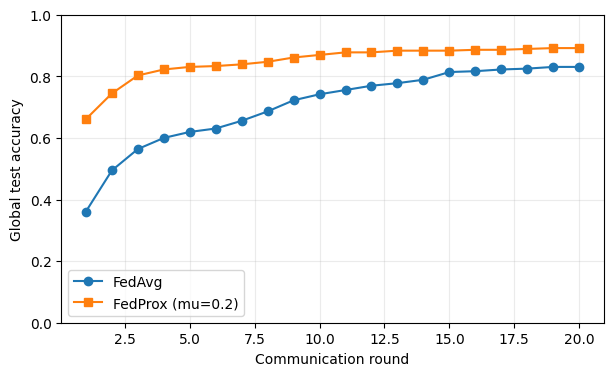

In [7]:
rounds = np.arange(1, len(fedavg_acc)+1)

fig, ax = plt.subplots(figsize = (7, 4))
ax.plot(rounds, fedavg_acc, marker="o", label="FedAvg")
ax.plot(rounds, fedprox_acc, marker="s", label="FedProx (mu=0.2)")
ax.set_xlabel("Communication round")
ax.set_ylabel("Global test accuracy")
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

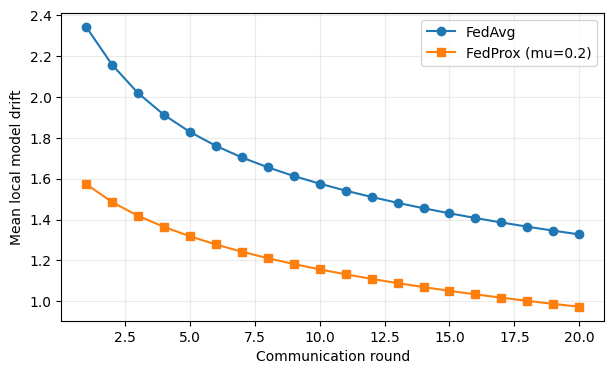

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rounds, fedavg_drift, marker="o", label="FedAvg")
ax.plot(rounds, fedprox_drift, marker="s", label="FedProx (mu=0.2)")
ax.set_xlabel("Communication round")
ax.set_ylabel("Mean local model drift")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


## 6. Result and research interpretation

Using this fixed seed and setup:

- FedAvg final accuracy: **0.831**
- FedProx final accuracy: **0.892**
- FedAvg average drift: **1.641**
- FedProx average drift: **1.185**

This mini-experiment supports the intended mechanism:

> When non-IID clients perform very different amounts of local work, FedProx constrains local deviation and improves the global result in this setup.

### Research extensions

1. Sweep `mu` instead of fixing it to 0.2.
2. Change the local-step schedule.
3. Compare IID and non-IID partitions.
4. Add partial client participation.
5. Repeat with several random seeds and report mean ± standard deviation.

That final step is what turns a classroom demo into a more credible research experiment.
